# <center>**M2 Bio-informatique - Projet MLG**<center>
Réalisé par Théo Brugel et Benjamin Theuleau  
  
* <span style="color:lightgreen">Fini et validé</span>
* <span style="color:violet">Fini mais à valider</span>
* <span style="color:yellow">Point d'attention / à compléter</span>
* <span style="color:orange">En cours</span>
* <span style="color:red">Reste à faire</span>  
  
Pour plus d'information sur l'avancement du projet => README.md

# <span style="color:lightgreen">Contexte de l’étude et objectifs</span>
Depuis le début de l’année 2026, 343 cas de paludisme ont été enregistrés sur l’île de Mayotte, dont 76 acquis localement et 238 importés, majoritairement en provenance des Comores (Bulletin Surveillance Regionale Mayotte). Le paludisme est transmis à l’être humain par la piqûre d’un moustique du genre Anopheles, lui-même infecté par le parasite du genre Plasmodium après avoir piqué un humain impaludé.<br>
Les modifications de l'occupation du sol, notamment l'urbanisation, la disparition de la végétation ou la transformation des espaces agricoles, peuvent influencer les conditions environnementales favorables à certaines espèces de moustiques. Les Anopheles sont fréquemment associés aux habitats aquatiques, aux zones agricoles/pastorales et à des conditions paysagères favorables aux gîtes larvaires ; les études de télédétection montrent notamment des associations avec l’altitude, l’humidité du sol, la distance aux cours d’eau, le NDVI et les classes d’occupation du sol.

<i>Question à laquelle vous devez répondre : Dans quels contextes paysagers les moustiques du genre Anopheles sont-ils détectés en 2024, et peut-on prédire leur présence sur l’ensemble de la zone d’étude à partir de variables environnementales issues d’images satellites.</i>

À partir de 2 images satellites Sentinel-2 acquises à des dates différentes, vous devrez analyser et quantifier l'évolution de l'occupation du sol à Mayotte, avec une attention particulière portée aux environnements de vis des moustiques.<br>
Cet exercice vous fera mobiliser les méthodes de traitement d'images et de machine learning étudiées en TP afin de produire une analyse spatiale argumentée des changements environnementaux pouvant expliquer en partie la présence du vecteur et d’en prédire sa probable présence sur les zones ou cleui-ci n’a pas été enregistré.

# <span style="color:yellow">Bibliographie</span>
* ABDEL-MALEK Albert A., ABDEL-AAL Motamed A. Study of the dispersion and flight range of Anopheles sergenti Theo. in Siwa Oasis using radioactive isotopes as markers. *Bull World Health Organ.* 1966;35(6):968-973. https://pmc.ncbi.nlm.nih.gov/articles/PMC2476271/
* EGGEN, Michael, OZDOGAN, Mutlu, ZAITCHIK, Benjamin F., et al. Land cover classification in complex and fragmented agricultural landscapes of the Ethiopian highlands. *Remote Sensing*, 2016, vol. 8, no 12, p. 1020. https://www.mdpi.com/2072-4292/8/12/1020
* EJERCTTO Antonio, URBINO Cornelio M. Flight range of gravid and newly emerged Anopheles. *Bull World Health Organ.* 1951;3(4):663-671. https://pmc.ncbi.nlm.nih.gov/articles/PMC2554024/ 
* NGUYEN, Huong Thi Thanh, DOAN, Trung Minh, TOMPPO, Erkki, et al. Land Use/land cover mapping using multitemporal Sentinel-2 imagery and four classification methods—A case study from Dak Nong, Vietnam. *Remote Sensing*, 2020, vol. 12, no 9, p. 1367. https://www.mdpi.com/2072-4292/12/9/1367
* SOVANN, Chansopheaktra, OLIN, Stefan, MANSOURIAN, Ali, et al. Importance of spectral information, seasonality, and topography on land cover classification of tropical land cover mapping. *Remote Sensing*, 2025, vol. 17, no 9, p. 1551. https://www.mdpi.com/2072-4292/17/9/1551#article-metrics-citations

# <span style="color:violet">Organisation des répertoires</span>
|_ MLG/  
&emsp;|_ projet_MLG.ipynb  
&emsp;|_ images/  
&emsp;&emsp;|_ Sentinel2_2019/  
&emsp;&emsp;|_ Sentinel2_2024/  
&emsp;&emsp;|_ Inventaire.tif  
&emsp;&emsp;|_ mayotte_mnt.tif

# <span style="color:yellow">Librairies</span>

In [2]:
import numpy as np
import os
import pandas as pd
import random
import rastereasy as re
import sklearn as skl

# <span style="color:yellow">Préparation des images</span>

Les deux images fournies sont au format Sentinel-2 du programme Copernicus de l'ESA. C'est-à-dire que nous disposons de deux dossiers (un par date d'image) contenant chaque bandes séparées.  
Pour pouvoir les utiliser dans la suite de notre projet, nous allons stacker les bandes et les rééchantillonner afin qu'elles soient toutes à une même résolution (ici 10m/pixel).  
Nous produirons ensuite une version découpée de nos images autour de la zone d'intérêt, la zone de recensement des moustiques (Inventaire.tif) car, *a priori*, c'est seulement celle-ci qui nous intéresse. Nous garderons tout de même une version complète centrée sur l'île entière au cas où elle nous serve dans la suite de ce projet.

In [42]:
# Pour chacune des deux dates, nous stackons l'ensemble des bandes au sein d'une seule image

# variables
# Chemin vers les images
s2_folder = ["./images/Sentinel2_2019/GRANULE/L2A_T38LNL_A021510_20190805T072207/IMG_DATA", "./images/Sentinel2_2024/GRANULE/L2A_T38LNL_A038985_20240823T072200/IMG_DATA",]
resolutions = {"R10m": ["B02", "B03", "B04", "B08",], "R20m": ["B01", "B05", "B06", "B07", "B8A", "B11", "B12",],}
# Liste des bandes
bands_s2_name = ["B01", "B02", "B03", "B04", "B05", "B06", "B07", "B08", "B8A", "B11", "B12",]
bands_name = {"AC":1, "B":2, "G":3, "R":4, "RE1":5, "RE2":6, "RE3":7, "NIR":8, "NNIR":9, "SWIR1":10, "SWIR2":11,}

# Création des deux images stackées
years = [2019, 2024,]
for path, year in zip(s2_folder, years):
    # Liste de l'ensemble des bandes contenues dans les dossiers pour les résolutions 10 et 20m
    band2add_R10 = os.listdir(f"{path}/R10m/")
    band2add_R20 = os.listdir(f"{path}/R20m/")

    mayotte = re.open(f"{path}/R20m/{band2add_R20[1]}").resample(10)

    # Pour chacun des deux dossiers, on parcours les bandes qu'on veut récupérer (cf bands_s2_name)
    # puis on les ajoutes au stack avec une résolution à 10m (native pour BGRNIR, rééchantillonnée pour les autres)
    for band in bands_s2_name[1:]:
        if band in resolutions["R10m"]:
            for img in band2add_R10:
                if ".aux.xml" not in img and band in img:
                    band2add = re.open(f"{path}/R10m/{img}")
                    mayotte.stack(band2add, inplace=True)

        elif band in resolutions["R20m"]:
            for img in band2add_R20:
                if ".aux.xml" not in img and band in img:
                    band2add_resampled = re.open(f"{path}/R20m/{img}").resample(10)
                    mayotte.stack(band2add_resampled, inplace=True)

    # On remet au propre le nom des bandes puis on enregistre le stack sur le disque dur
    mayotte.change_names(bands_name)
    mayotte.save(f"./images/mayotte_{year}.tif")

# Centrage et découpage des images sur l'île
islands = ["./images/mayotte_2019.tif", "./images/mayotte_2024.tif",]

for isle in islands:
    isle_resize = re.open(isle).crop(area = ((0, 4000), (0, 3500)))
    isle_resize.save(isle)

# Centrage et découpage des images sur la zone de piègeage
traps = re.open("./images/inventaire_resize_qgis.tif")

for isle, year in zip(islands, years):
    isle_trap_area, inventaire_resize = re.extract_common_areas(re.open(isle), traps)
    isle_trap_area.save(f"./images/traps_area_{year}.tif")
inventaire_resize.save("./images/inventaire_resize.tif")

In [34]:
# Vérification des sorties
mayotte_2019 = re.open("./images/traps_area_2019.tif")
mayotte_2024 = re.open("./images/traps_area_2024.tif")
traps = re.open("./images/inventaire_resize.tif")

print(np.shape(mayotte_2019), np.shape(mayotte_2024), np.shape(traps))
print(mayotte_2019.info(), mayotte_2024.info(), traps.info())

(1237, 1309) (1237, 1309) (1237, 1309)
- Size of the image:
   - Rows (height): 1237
   - Cols (width): 1309
   - Bands: 11
- Spatial resolution: 10.0  meters / degree (depending on projection system)
- Central point latitude - longitude coordinates: (-12.72710184, 45.09691933)
- Driver: GTiff
- Data type: uint16
- Projection system: EPSG:32738

- Given names for spectral bands: 
   {'AC': 1, 'B': 2, 'G': 3, 'R': 4, 'RE1': 5, 'RE2': 6, 'RE3': 7, 'NIR': 8, 'NNIR': 9, 'SWIR1': 10, 'SWIR2': 11}


- Size of the image:
   - Rows (height): 1237
   - Cols (width): 1309
   - Bands: 11
- Spatial resolution: 10.0  meters / degree (depending on projection system)
- Central point latitude - longitude coordinates: (-12.72710184, 45.09691933)
- Driver: GTiff
- Data type: uint16
- Projection system: EPSG:32738

- Given names for spectral bands: 
   {'AC': 1, 'B': 2, 'G': 3, 'R': 4, 'RE1': 5, 'RE2': 6, 'RE3': 7, 'NIR': 8, 'NNIR': 9, 'SWIR1': 10, 'SWIR2': 11}


- Size of the image:
   - Rows (height): 

# <span style="color:yellow">**Objectif 1 : exploration des images satellites**</span>

## <span style="color:yellow">Caractéristiques principales des images</span>

In [13]:
# Affichage des informations de chacune des deux images
print(mayotte_2019.info())
print(mayotte_2024.info())

- Size of the image:
   - Rows (height): 1237
   - Cols (width): 1309
   - Bands: 11
- Spatial resolution: 10.0  meters / degree (depending on projection system)
- Central point latitude - longitude coordinates: (-12.72710184, 45.09691933)
- Driver: GTiff
- Data type: uint16
- Projection system: EPSG:32738

- Given names for spectral bands: 
   {'AC': 1, 'B': 2, 'G': 3, 'R': 4, 'RE1': 5, 'RE2': 6, 'RE3': 7, 'NIR': 8, 'NNIR': 9, 'SWIR1': 10, 'SWIR2': 11}


None
- Size of the image:
   - Rows (height): 1237
   - Cols (width): 1309
   - Bands: 11
- Spatial resolution: 10.0  meters / degree (depending on projection system)
- Central point latitude - longitude coordinates: (-12.72710184, 45.09691933)
- Driver: GTiff
- Data type: uint16
- Projection system: EPSG:32738

- Given names for spectral bands: 
   {'AC': 1, 'B': 2, 'G': 3, 'R': 4, 'RE1': 5, 'RE2': 6, 'RE3': 7, 'NIR': 8, 'NNIR': 9, 'SWIR1': 10, 'SWIR2': 11}


None


| | <center>Sentinel2_2019<center> | <center>Sentinel2_2024<center> |
|-|-|-|
| <center>**Date d'acquisition**<center> | <center>05/08/2019<center> | <center>23/08/2024<center> |
| <center>**Résolution spatiale**<center> | <center>10 mètres<center> | <center>10 mètres<center> |
| <center>**Bandes spectrales**<center> |<center>Coastal Aerosol / Blue / Green /<br>Red / Red Edge 1,2,3 / Near Infra-Red /<br>Narrow Near Infra-Red / Shortwave Infra-Red 1,2<center>|<center>Coastal Aerosol / Blue / Green /<br>Red / Red Edge 1,2,3 / Near Infra-Red /<br>Narrow Near Infra-Red / Shortwave Infra-Red 1,2<center>|
| <center>**Dimensions**<center> | <center>1447x1757 pixels<br>soit 14,47x17,57 km<center> | <center>1447x1757 pixels<br>soit 14,47x17,57 km<center> |

## <span style="color:violet">Visualisation des images</span>

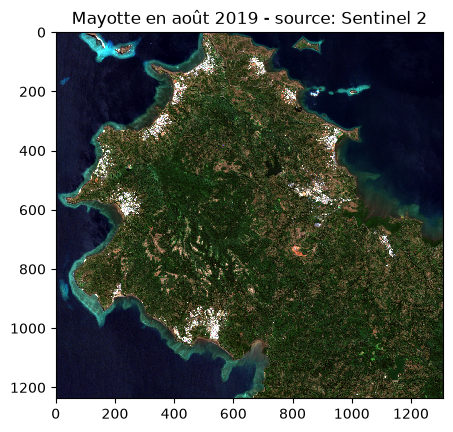

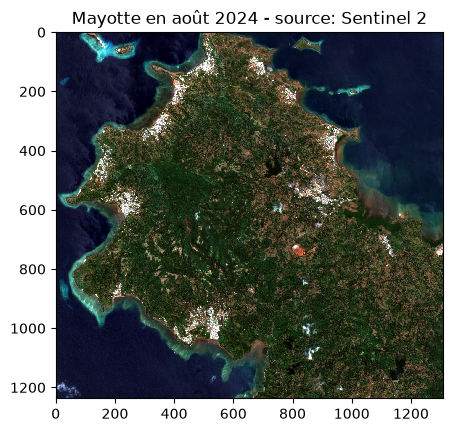

In [14]:
# Compositions colorées de Mayotte en 2019 et 2024
mayotte_2019.colorcomp(["R", "G", "B",], extent = "pixel", title = "Mayotte en août 2019 - source: Sentinel 2")
mayotte_2024.colorcomp(["R", "G", "B",], extent = "pixel", title = "Mayotte en août 2024 - source: Sentinel 2")

## <span style="color:yellow">Zonage autour des pièges</span>
Pour décrire l'environnement autour des pièges, nous découpons des imagettes de 200x200 pixels, c'est-à-dire que nous gardons un périmètre d'un kilomètre. Le choix de cette distance tient au fait que dans la littérature, la distance de vol des moustiques du genre *Anopheles* semble allée de 500 mètres à 1000 mètres selon les espèces (EJERCITO A., M. URBINO C., 1951 ; ABDEL-MALEK A.A., ABDEL-AAL M.A., 1966).  

In [15]:
if not os.path.exists("./images/traps/"):
    os.makedirs("./images/traps/2019/") 
    os.makedirs("./images/traps/2024/")

# Récupération des coordonnées de chacun des pièges
trap_coord_list = []
traps_np = traps.numpy_channel_first()[0]

for i in range(len(traps_np)):
    for j in range(len(traps_np[i])):
        if traps_np[i][j] > 0:
            trap_coord_list.append((i, j))

# Découpage d'un buffer autour de chaque piège
for i, trap_coord in enumerate(trap_coord_list):
    
    # Création des coordonnées d'un crop de 1000m autour de chaque piège
    deb_row = trap_coord[0] - 100
    end_row = trap_coord[0] + 100
    deb_col = trap_coord[1] - 100
    end_col = trap_coord[1] + 100
    
    # Découpage des images
    img_temp_2019 = mayotte_2019.crop(area = ((deb_row, end_row), (deb_col, end_col)))
    img_temp_2024 = mayotte_2024.crop(area = ((deb_row, end_row), (deb_col, end_col)))

    # Enregistrement des imagettes
    img_temp_2019.save(f"./images/traps/2019/trap{i}_2019.tif")
    img_temp_2024.save(f"./images/traps/2024/trap{i}_2024.tif")

- Size of the image:
   - Rows (height): 200
   - Cols (width): 200
   - Bands: 11
- Spatial resolution: 10.0  meters / degree (depending on projection system)
- Central point latitude - longitude coordinates: (-12.74307733, 45.07226994)
- Driver: GTiff
- Data type: uint16
- Projection system: EPSG:32738

- Given names for spectral bands: 
   {'AC': 1, 'B': 2, 'G': 3, 'R': 4, 'RE1': 5, 'RE2': 6, 'RE3': 7, 'NIR': 8, 'NNIR': 9, 'SWIR1': 10, 'SWIR2': 11}




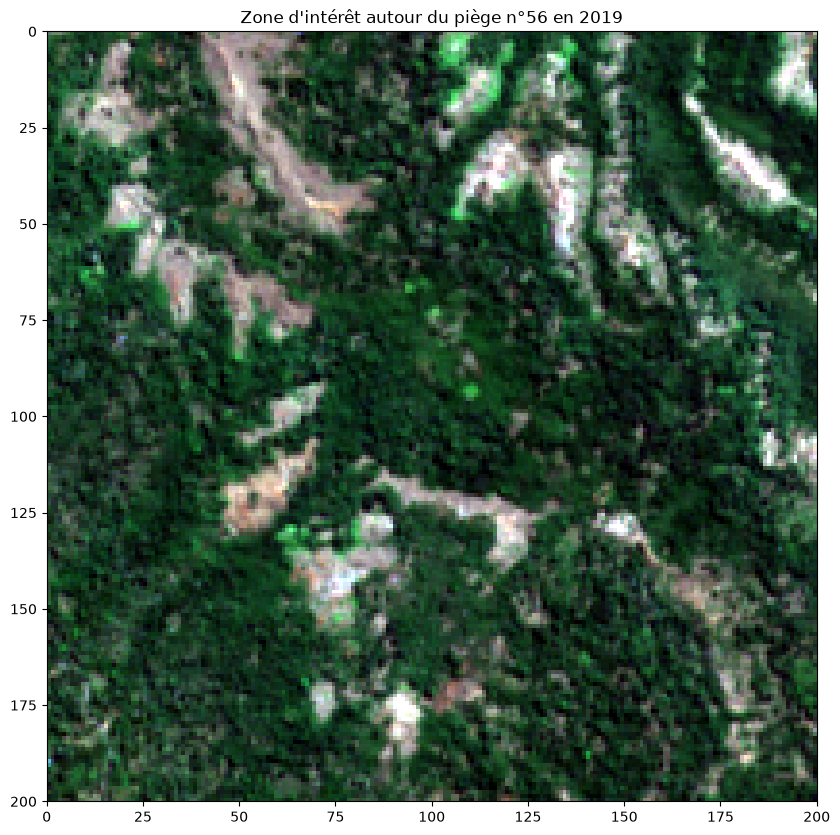

- Size of the image:
   - Rows (height): 200
   - Cols (width): 200
   - Bands: 11
- Spatial resolution: 10.0  meters / degree (depending on projection system)
- Central point latitude - longitude coordinates: (-12.74307733, 45.07226994)
- Driver: GTiff
- Data type: uint16
- Projection system: EPSG:32738

- Given names for spectral bands: 
   {'AC': 1, 'B': 2, 'G': 3, 'R': 4, 'RE1': 5, 'RE2': 6, 'RE3': 7, 'NIR': 8, 'NNIR': 9, 'SWIR1': 10, 'SWIR2': 11}




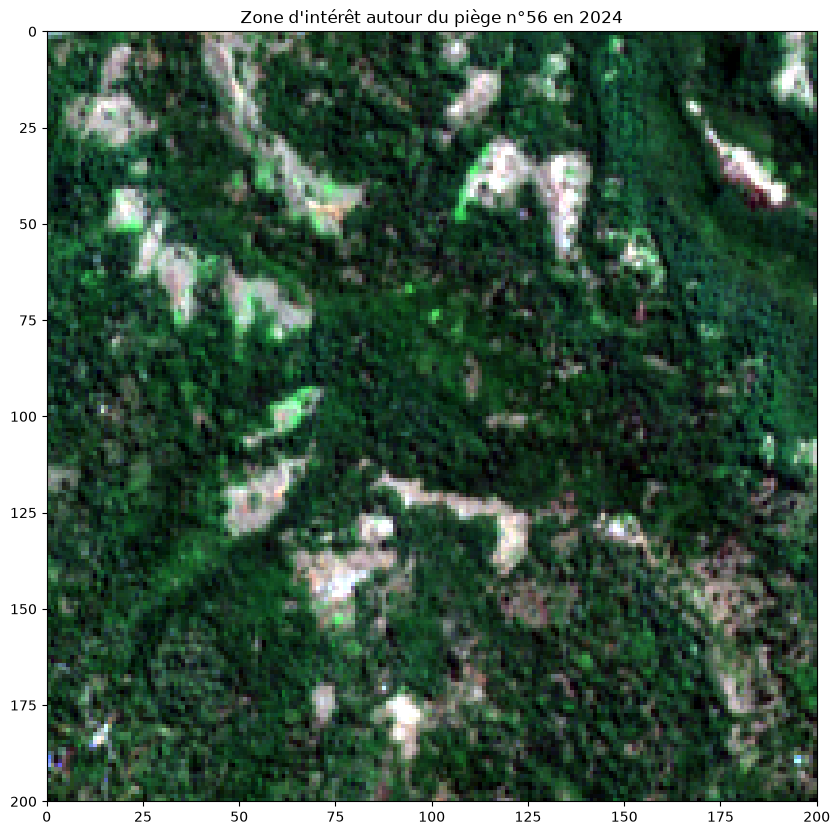

In [16]:
# Exemple de zones autour de pièges
select_trap = random.randint(0, 99)

trap_2019 = re.open(f"./images/traps/2019/trap{select_trap}_2019.tif")
trap_2019.info()
trap_2019.colorcomp(["R", "G", "B"], fig_size = (10,10), extent = "pixel", title = f"Zone d'intérêt autour du piège n°{select_trap} en 2019")

trap_2024 = re.open(f"./images/traps/2024/trap{select_trap}_2024.tif")
trap_2024.info()
trap_2024.colorcomp(["R", "G", "B"], fig_size = (10,10), extent = "pixel", title = f"Zone d'intérêt autour du piège n°{select_trap} en 2024")

# <span style="color:orange">**Objectif 2 : Calcul et comparaison des indicateurs spectraux**</span>

## <span style="color:yellow">Calcul des indices spectraux</span>
Afin de caractériser le terrain à Mayotte dans la zone où se trouve les pièges, nous ajoutons à nos images des indicateurs spectraux. Ces indicateurs sont calculés à partir des différentes bandes spectrales des images sentinel-2. Quatres indicateurs ont été retenus :  
* NDVI (Normalized Difference Vegetation Index) : Indice classique de description de la couverture végétale du sol (EGGEN et al., 2016 ; NGUYEN et al., 2020 ; SOVANN et al., 2025).
* MCARI (Modified Chlorophyll Absorption Ratio Index) : Indice de description de la couverture végétale du sol qui prend en compte la réflectance du sol quand la végétation est éparse (SOVANN et al., 2025).
* NDTI (Normalized Difference Tillage Index) : Indice de description des surfaces agricoles labourées (SOVANN et al., 2025).
* NDBI (Normalized Difference Built-up Index) : Indice de descritpion des surfaces bâties.
* MNDWI (Modified Normalized Difference Water Index) : Indice de caractérisation des surfaces en eau qui prend en compte la réflectance des surfaces bâties

In [35]:
def calcul_indicateurs_spectraux(image_name: str) -> None:
    """
    Fonction de calcul d'indicateurs spectraux. Une image est fournie en entrée,
    on y récupère les bandes Red, Green, RE1, RE2, NIR, SWIR1, SWIR2 qui sont converties
    au format numpy et en float puis les indicateurs suivant sont calculés:
        - NDVI (Normalized Difference Vegetation Index)
        - MCARI (Modified Chlorophyll Absorption Ratio Index)
        - NDTI (Normalized Difference Tillage Index)
        - NDBI (Normalized Difference Built-up Index)
        - MNDWI (Modified Normalized Difference Water Index)
    Enfin, les indicateurs sont ajoutés comme bandes supplémentaires à l'image.
    
    Entrée :
        image_name (str) : chemin relatif jusqu'à une image au format jp2 ou tif
    
    Sortie :
        None
    """
    img_temp = re.open(image_name)
    
    # Sélection des bandes
    r = img_temp.select_bands("R").numpy_channel_first() / 10000
    nir = img_temp.select_bands("NIR").numpy_channel_first() / 10000
    re1 = img_temp.select_bands("RE1").numpy_channel_first() / 10000
    re2 = img_temp.select_bands("RE2").numpy_channel_first() / 10000
    swir1 = img_temp.select_bands("SWIR1").numpy_channel_first() / 10000
    swir2 = img_temp.select_bands("SWIR2").numpy_channel_first() / 10000
    g = img_temp.select_bands("G").numpy_channel_first() / 10000

    # Calcul des indicateurs
    ndvi = (nir - r) / (nir + r + 1e-6)
    mcari = ((re2 - re1) - 0.2 * (re2 - r)) * (re2 / (re1 + 1e-6))
    ndti = (swir1 - swir2) / (swir1 + swir2 + 1e-6)
    ndbi = (swir1 - nir) / (swir1 + nir + 1e-6)
    mndwi = (g - swir1) / (g + swir1 + 1e-6)

    # Sauvegarde de l'imagette
    img_temp.add_band(ndvi, name_band = "NDVI", inplace = True)
    img_temp.add_band(mcari, name_band = "MCARI", inplace = True)
    img_temp.add_band(ndti, name_band = "NDTI", inplace = True)
    img_temp.add_band(ndbi, name_band = "NDBI", inplace = True)
    img_temp.add_band(mndwi, name_band = "MNDWI", inplace = True)
    img_temp.save(image_name) 

### Calcul des indices spectraux pour les images de Mayotte

In [43]:
# calcul des indicateurs et ajout aux images de Mayotte
# variables
mayotte = ["./images/traps_area_2019.tif", "./images/traps_area_2024.tif",]

# Boucle principale
for img in mayotte:
    calcul_indicateurs_spectraux(img)

In [19]:
# Vérification des images après intégration des indicateurs
mayotte_2019 = re.open("./images/traps_area_2019.tif")
print(np.shape(mayotte_2019.numpy_channel_first()))
mayotte_2019.info()

mayotte_2024 = re.open("./images/traps_area_2024.tif")
print(np.shape(mayotte_2024.numpy_channel_first()))
mayotte_2024.info()

(16, 1237, 1309)
- Size of the image:
   - Rows (height): 1237
   - Cols (width): 1309
   - Bands: 16
- Spatial resolution: 10.0  meters / degree (depending on projection system)
- Central point latitude - longitude coordinates: (-12.72710184, 45.09691933)
- Driver: GTiff
- Data type: float64
- Projection system: EPSG:32738

- Given names for spectral bands: 
   {'AC': 1, 'B': 2, 'G': 3, 'R': 4, 'RE1': 5, 'RE2': 6, 'RE3': 7, 'NIR': 8, 'NNIR': 9, 'SWIR1': 10, 'SWIR2': 11, 'NDVI': 12, 'MCARI': 13, 'NDTI': 14, 'NDBI': 15, 'MNDWI': 16}


(16, 1237, 1309)
- Size of the image:
   - Rows (height): 1237
   - Cols (width): 1309
   - Bands: 16
- Spatial resolution: 10.0  meters / degree (depending on projection system)
- Central point latitude - longitude coordinates: (-12.72710184, 45.09691933)
- Driver: GTiff
- Data type: float64
- Projection system: EPSG:32738

- Given names for spectral bands: 
   {'AC': 1, 'B': 2, 'G': 3, 'R': 4, 'RE1': 5, 'RE2': 6, 'RE3': 7, 'NIR': 8, 'NNIR': 9, 'SWIR1': 1

### Calcul des indices spectraux pour les imagettes autour des pièges à moustiques

In [20]:
# calcul des indicateurs et ajout aux imagettes
# variables
traps = "./images/traps/"
years = ["2019", "2024",]

# Boucle principale
for year in years:
    for trap in os.listdir(f"{traps}/{year}/"):
        calcul_indicateurs_spectraux(f"{traps}/{year}/{trap}")

In [21]:
# Vérification des imagettes après intégration des indicateurs
select_trap = random.randint(0, 99)

trap_2019 = re.open(f"./images/traps/2019/trap{select_trap}_2019.tif")
print(np.shape(trap_2019.numpy_channel_first()))
trap_2019.info()

trap_2024 = re.open(f"./images/traps/2024/trap{select_trap}_2024.tif")
print(np.shape(trap_2024.numpy_channel_first()))
trap_2024.info()

(16, 200, 200)
- Size of the image:
   - Rows (height): 200
   - Cols (width): 200
   - Bands: 16
- Spatial resolution: 10.0  meters / degree (depending on projection system)
- Central point latitude - longitude coordinates: (-12.70437208, 45.07806178)
- Driver: GTiff
- Data type: float64
- Projection system: EPSG:32738

- Given names for spectral bands: 
   {'AC': 1, 'B': 2, 'G': 3, 'R': 4, 'RE1': 5, 'RE2': 6, 'RE3': 7, 'NIR': 8, 'NNIR': 9, 'SWIR1': 10, 'SWIR2': 11, 'NDVI': 12, 'MCARI': 13, 'NDTI': 14, 'NDBI': 15, 'MNDWI': 16}


(16, 200, 200)
- Size of the image:
   - Rows (height): 200
   - Cols (width): 200
   - Bands: 16
- Spatial resolution: 10.0  meters / degree (depending on projection system)
- Central point latitude - longitude coordinates: (-12.70437208, 45.07806178)
- Driver: GTiff
- Data type: float64
- Projection system: EPSG:32738

- Given names for spectral bands: 
   {'AC': 1, 'B': 2, 'G': 3, 'R': 4, 'RE1': 5, 'RE2': 6, 'RE3': 7, 'NIR': 8, 'NNIR': 9, 'SWIR1': 10, 'SWIR

## <span style="color:yellow">Visualisation des indices spectraux</span>

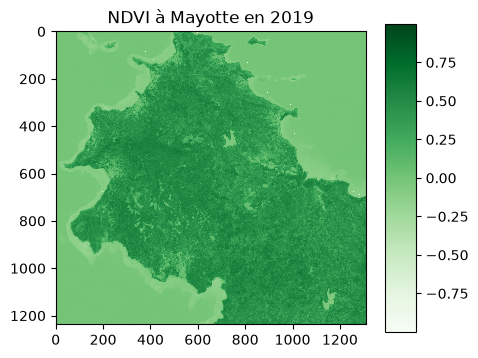

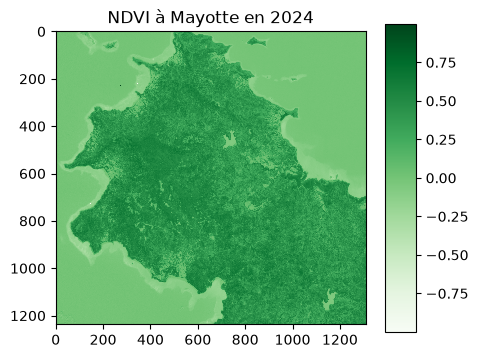

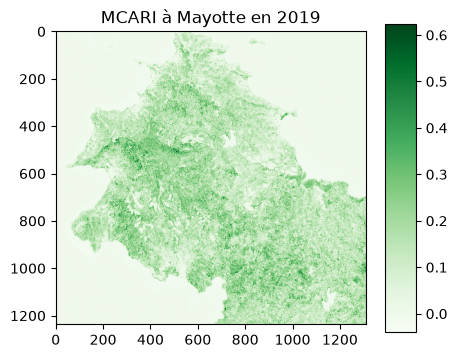

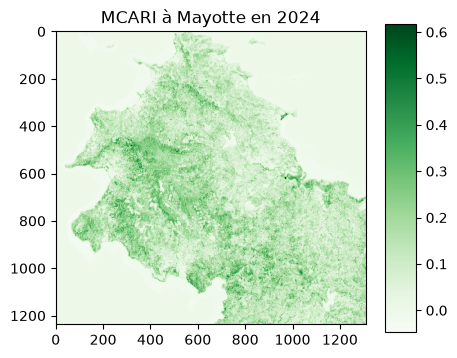

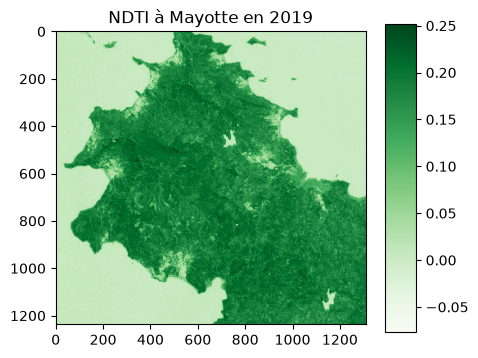

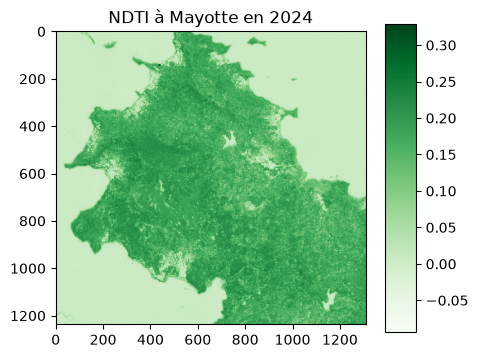

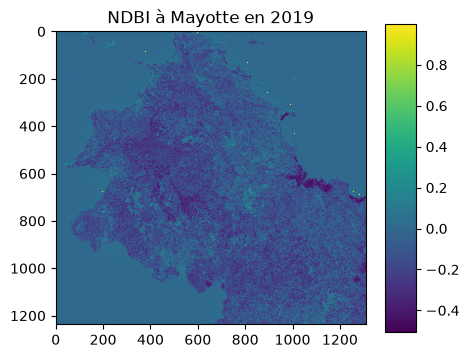

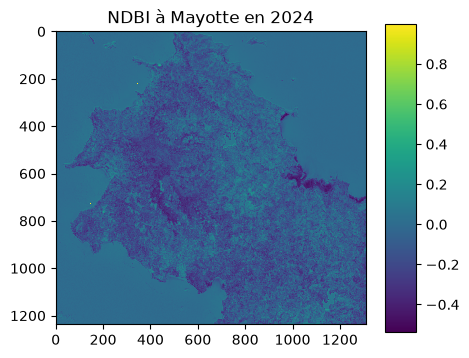

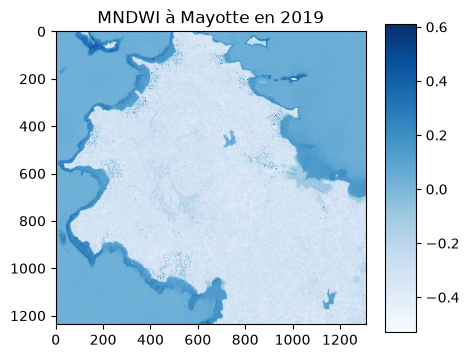

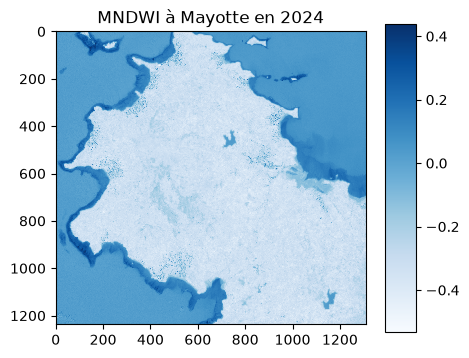

In [22]:
mayotte_2019.visu(["NDVI"], extent = "pixel", title = "NDVI à Mayotte en 2019", cmap = "Greens", colorbar = True)
mayotte_2024.visu(["NDVI"], extent = "pixel", title = "NDVI à Mayotte en 2024", cmap = "Greens", colorbar = True)

mayotte_2019.visu(["MCARI"], extent = "pixel", title = "MCARI à Mayotte en 2019", cmap = "Greens", colorbar = True)
mayotte_2024.visu(["MCARI"], extent = "pixel", title = "MCARI à Mayotte en 2024", cmap = "Greens", colorbar = True)

mayotte_2019.visu(["NDTI"], extent = "pixel", title = "NDTI à Mayotte en 2019", cmap = "Greens", colorbar = True)
mayotte_2024.visu(["NDTI"], extent = "pixel", title = "NDTI à Mayotte en 2024", cmap = "Greens", colorbar = True)

mayotte_2019.visu(["NDBI"], extent = "pixel", title = "NDBI à Mayotte en 2019", cmap = "viridis", colorbar = True)
mayotte_2024.visu(["NDBI"], extent = "pixel", title = "NDBI à Mayotte en 2024", cmap = "viridis", colorbar = True)

mayotte_2019.visu(["MNDWI"], extent = "pixel", title = "MNDWI à Mayotte en 2019", cmap = "Blues", colorbar = True)
mayotte_2024.visu(["MNDWI"], extent = "pixel", title = "MNDWI à Mayotte en 2024", cmap = "Blues", colorbar = True)

## <span style="color:orange">Variation des indices spectraux entre 2019 et 2024</span>

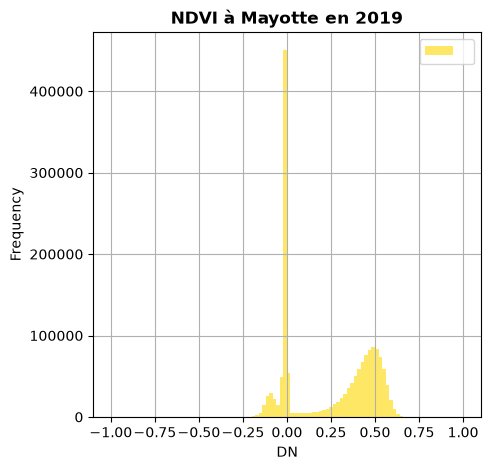

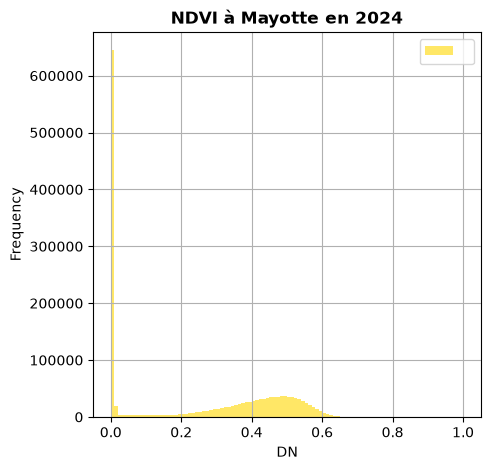

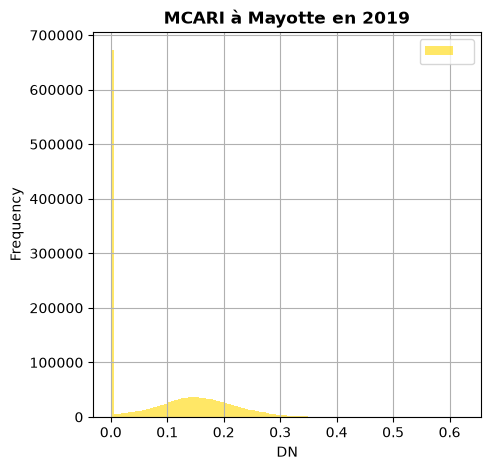

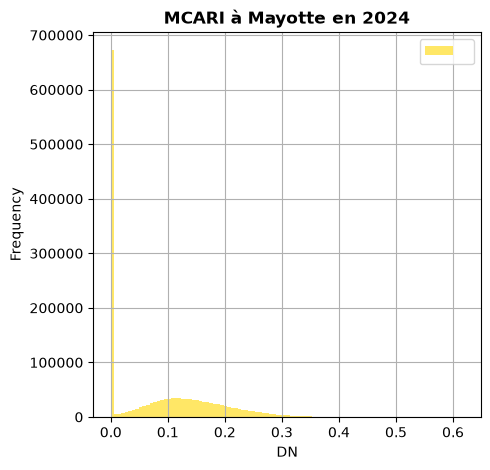

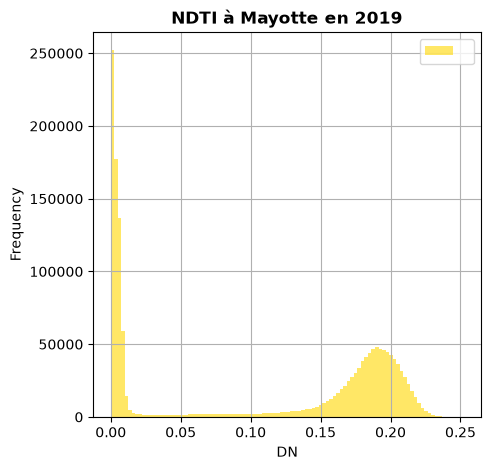

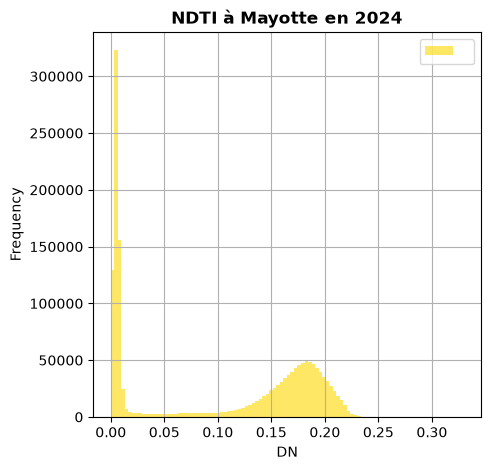

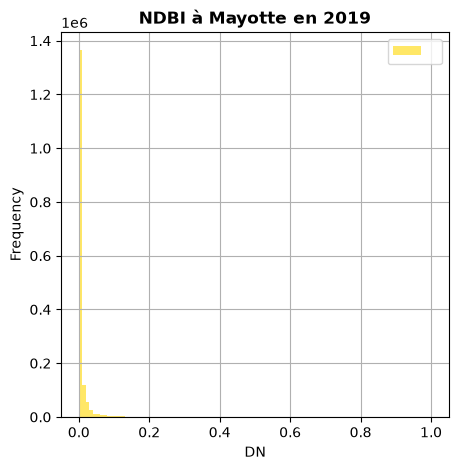

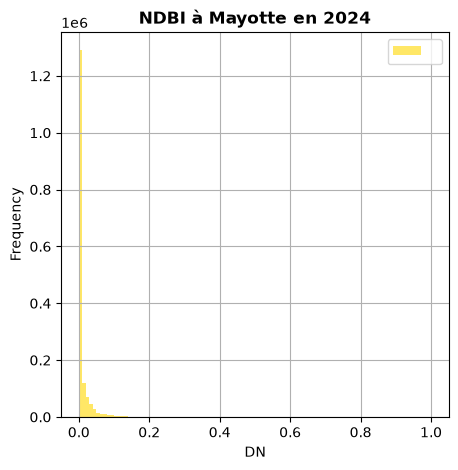

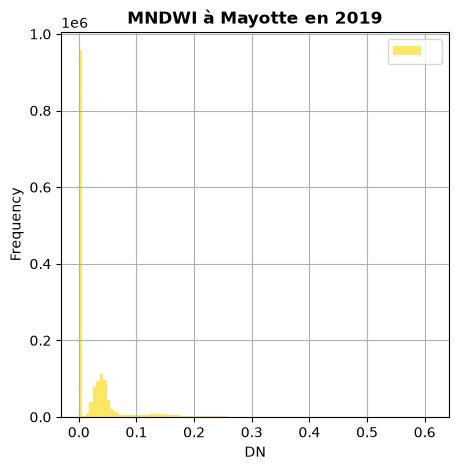

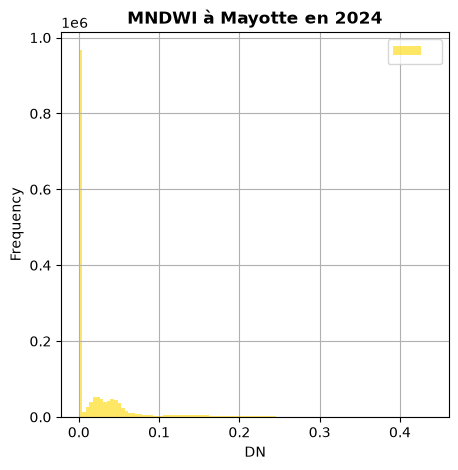

In [ ]:
mayotte_2019.hist(bands = "NDVI", xmin = 0, title = "NDVI à Mayotte en 2019")
mayotte_2024.hist(bands = "NDVI", xmin = 0, title = "NDVI à Mayotte en 2024")

mayotte_2019.hist(bands = "MCARI", xmin = 0, title = "MCARI à Mayotte en 2019")
mayotte_2024.hist(bands = "MCARI", xmin = 0, title = "MCARI à Mayotte en 2024")

mayotte_2019.hist(bands = "NDTI", xmin = 0, title = "NDTI à Mayotte en 2019")
mayotte_2024.hist(bands = "NDTI", xmin = 0, title = "NDTI à Mayotte en 2024")

mayotte_2019.hist(bands = "NDBI", xmin = 0, title = "NDBI à Mayotte en 2019")
mayotte_2024.hist(bands = "NDBI", xmin = 0, title = "NDBI à Mayotte en 2024")

mayotte_2019.hist(bands = "MNDWI", xmin = 0, title = "MNDWI à Mayotte en 2019")
mayotte_2024.hist(bands = "MNDWI", xmin = 0, title = "MNDWI à Mayotte en 2024")

In [24]:
# variables
indices_list = ["NDVI", "MCARI", "NDTI", "NDBI", "MNDWI",]
indices_val_summary = {}

# Calcul de l'évolution des indices spectraux entre 2019 et 2024
for indice in indices_list:
    mean_indice_2019 = np.mean(mayotte_2019.select_bands(indice).numpy_channel_first())
    mean_indice_2024 = np.mean(mayotte_2024.select_bands(indice).numpy_channel_first())
    std_indice_2019 = np.std(mayotte_2019.select_bands(indice).numpy_channel_first())
    std_indice_2024 = np.std(mayotte_2024.select_bands(indice).numpy_channel_first())
    delta_indice = np.mean(mayotte_2024.select_bands(indice).numpy_channel_first() - mayotte_2019.select_bands(indice).numpy_channel_first())
    indices_val_summary[indice] = {"mean_2019": mean_indice_2019, "mean_2024": mean_indice_2024, "std_2019": std_indice_2019, "std_2024": std_indice_2024, "delta": delta_indice,}

print(pd.DataFrame(indices_val_summary).transpose())

       mean_2019  mean_2024  std_2019  std_2024     delta
NDVI    0.243951   0.237219  0.242301  0.239688 -0.006731
MCARI   0.089985   0.082397  0.093538  0.089919 -0.007588
NDTI    0.107814   0.101829  0.089800  0.084273 -0.005985
NDBI   -0.072830  -0.064487  0.100471  0.100559  0.008343
MNDWI  -0.152453  -0.158137  0.188811  0.191017 -0.005684


*A priori*, les différents indicateurs spectraux utilisés pour caractériser la végétation, les zones agricoles, l'eau et le bâtie indiquent une évolution presque nul du paysage entre 2019 et 2024, avec un écart compris entre -0.006 et 0.006. On peut d'ailleurs noter que les valeurs moyennes des indicateurs pour chacune des deux années sont globalement faible, allant de -0.11 pour le MNDWI à 0.19 pour NDVI.  
Cependant, il est important de noter que ces indicateurs sont calculés sur une très large zone, un peu plus de 254 km², avec une répartition d'environ 50% de terres et 50% de mer. La moyenne d'un indicateur va pouvoir cacher des disparités importantes au sein d'un espace plus restreint, par exemple autour d'une bâtie comme une ville. Pour palier ce problème, et dans la mesure où le cycle de vie des moustiques n'a pas de phase aquatique en eau salée, il pourrait être pertinent de resserer la zone découpée autour des pièges afin d'éléminer un maximum de surface maritime.

# <span style="color:orange">**Objectif 3 : Classification de l'occupation du sol**</span>

## <span style="color:orange">Classification de l'occupation du sol</span>

### Choix des classes et de la méthode de classification
Afin de détecter précisémenent les changements d'occupation et d'usage du sol, nous allons réaliser une classification de l'occupation du sol.  
Dans un premier temps, nous devons définir des classes d'occupation du sol. L'objectif est d'avoir des classes représentatives des grandes catégories d'occupation du sol.
* surface bâtie
* végétation
* sol nu
* eau</br>
  
Il aurait été intéressant d'ajouté une cinquième classe caractérisant les espaces cultivés car ils sont plus propices à la formation de points d'eau stagnante que le simple sol nu, mais la résolution à dix mètres des images sentinel-2 ne permet pas de les distinguer du sol nu.

### Classification

In [16]:
# Ajout d'une bande de Modèle Numérique de Terrain
mnt = re.open("./images/traps_area_mnt.tif")
traps, mnt = re.extend_common_areas(mnt, re.open("./images/traps_area_2024.tif"))
traps.add_band(mnt.numpy_channel_first(), name_band = "MNT", inplace = True)

ValueError: Error: metadata dimensions do not match data dimensions

In [ ]:
# Taille du jeu d'entraînement
train_prop = 0.8
image_shape = np.shape(re.open("./images/traps_area_2019.tif").numpy_channel_first())
train_size = round(image_shape[1] * train_prop)

# Génération des jeux de test et train et stock les numpy_table en 2D dans des listes
images = ["./images/traps_area_2024.tif", "./images/classif_digit_2024.tif",] # Si finalement la classif nécessite qu'une seule image, il suffit juste de supprimer une des deux ici.
mayotte_train = []
mayotte_test = []

for image in images:
    img = re.open(image)
    img_train = img.crop(area = ((0, train_size), (0, image_shape[2])))
    img_test = img.crop(area = ((train_size, image_shape[1]), (0, image_shape[2])))
    mayotte_train.append(img_train.numpy_table())
    mayotte_test.append(img_test.numpy_table())

In [9]:
# Vérification
print(np.shape(mayotte_train[0]))
print(np.shape(mayotte_train[1]))
print(np.shape(mayotte_test[0]))
print(np.shape(mayotte_test[1]))

(1030740, 16)
(1030740, 1)
(257070, 16)
(257070, 1)


In [ ]:
# Création et entraînement du modèle
modeleRF = skl.ensemble.RandomForestClassifier(n_estimators=100, , class_weight="balanced_subsample")
predRF = modeleRF.fit(mayotte_train[0], mayotte_train[1])

ValueError: Input y contains NaN.

In [6]:
# Application de la classification sur l'image
predictionsRF = predRF.predict(mayotte_test[0])

In [14]:
# Métriques
print(skl.metrics.balanced_accuracy_score(predictionsRF, mayotte_test[1]))
print(skl.metrics.f1_score(predictionsRF, mayotte_test[1], average="macro"))
print(skl.metrics.classification_report(mayotte_test[1], predictionsRF))
# skl.metrics.ConfusionMatrixDisplay.from_predictions(mayotte_test[1], predictionsRF, cmap="Blues")

0.47664066513069847
0.27507971413305593
              precision    recall  f1-score   support

         0.0       0.90      0.98      0.94    288014
         1.0       0.55      0.06      0.10     23262
         2.0       0.44      0.16      0.23      6460
         3.0       0.35      0.28      0.31      2430
         4.0       0.60      0.03      0.06       860
         5.0       0.01      0.01      0.01      2297

    accuracy                           0.88    323323
   macro avg       0.48      0.25      0.28    323323
weighted avg       0.85      0.88      0.85    323323



c:\Users\benji\anaconda3\envs\MLG\Lib\site-packages\rastereasy\rastereasy.py:5385: UserWarning: Colorcomp with only one band. Grey level image printed
  warnings.warn(


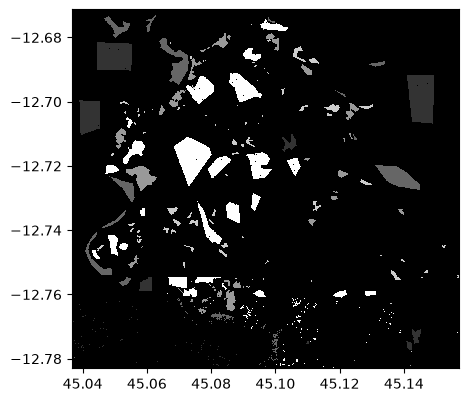

In [16]:
# Convertion de la prédiction en image
predictionsRF = predRF.predict(re.open("./images/traps_area_2024.tif").numpy_table())
visu_pred_np = re.table2image(predictionsRF, (1237, 1309))
visu_pred = re.open("./images/traps_area_2024.tif").add_band(visu_pred_np, name_band = "Classif_5_classes")
visu_pred.save("classif_RF_5_classes.tif")
visu_pred.colorcomp("Classif_5_classes")

### KMean

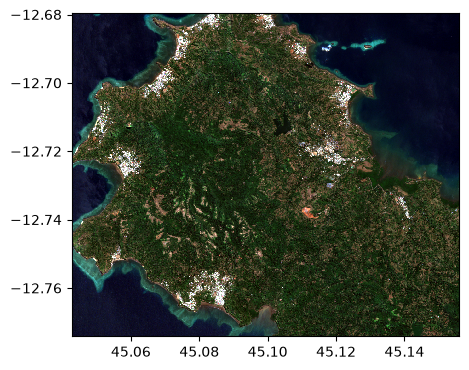

In [32]:
re.open("./images/traps_area_2019.tif").colorcomp(["R", "G", "B"])

In [69]:
# Création et entraînement du modèle
scaler = skl.preprocessing.StandardScaler()
train = scaler.fit_transform(re.open("./images/traps_area_2019.tif").numpy_table())
modelKM = skl.cluster.KMeans(n_clusters = 5, random_state = 777)
resultKM = modelKM.fit(train)

In [96]:
# Application de la classification sur l'image
train = scaler.fit_transform(re.open("./images/traps_area_2024.tif").numpy_table())
pred = resultKM.predict(train)

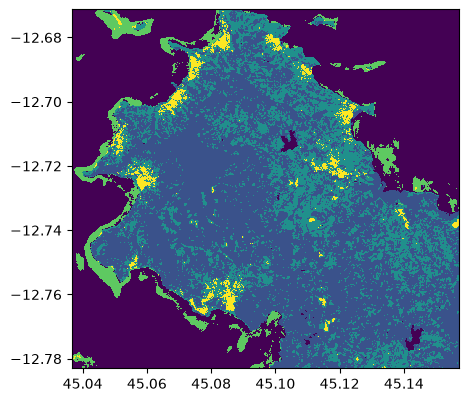

In [97]:
# Convertion de la prédiction en image
visu_pred_np = re.table2image(pred, (1237, 1309))
visu_pred = re.open("./images/traps_area_2024.tif").add_band(visu_pred_np, name_band = "Classif_5_classes")
visu_pred.save("./images/Kmean_5_classes_2024.tif")
visu_pred.visu("Classif_5_classes")

## <span style="color:red">Visualisation des résultats de la classification</span>

## <span style="color:red">Évaluation de la qualité de la classification</span>

# <span style="color:red">**Objectif 4 : Détection et quantification des changements**</span>

## <span style="color:red">Calcul des variations d'occupation du sol entre 2019 et 2024 à partir des classifications</span>

In [98]:
# Création d'une fonction d'évaluation des changements d'occupation du sol
def land_cover_evolution(image_1: str, image_2: str, band: str, lc_class: int = None, range: float = 0.05):
    if lc_class == None:
        img_1 = re.open(image_1).select_bands(band).numpy_channel_first()[0]
        img_2 = re.open(image_2).select_bands(band).numpy_channel_first()[0]
        changes_list = np.zeros((np.shape(img_1)))
        for i, line in enumerate(img_2):
            for j, val in enumerate(line):
                if (val - val * range) < img_1[i][j] < (val + val * range):
                    changes_list[i][j] = 1
        result = re.open(image_2).add_band(changes_list, name_band=f"{band}_EVO")
        result.save("./images/eval.tif")
    else:
        img_1 = re.open(image_1).select_bands(band).numpy_channel_first()[0]
        img_2 = re.open(image_2).select_bands(band).numpy_channel_first()[0]
        changes_list = np.zeros((np.shape(img_1)))
        for i, line in enumerate(img_2):
            for j, val in enumerate(line):
                if img_1[i][j] == lc_class and img_1[i][j] != val:
                    changes_list[i][j] = 1
                elif img_1[i][j] == lc_class and img_1[i][j] == val:
                    changes_list[i][j] = 0
                elif img_1[i][j] != lc_class:
                    changes_list[i][j] = -1
        result = re.open(image_2).add_band(changes_list, name_band=f"{band}_classe{lc_class}_EVO")
        result.save("./images/eval.tif")
    return

In [ ]:
# Variable
classif_2019 = "./images/Kmean_5_classes_2019.tif"
classif_2024 = "./images/Kmean_5_classes_2024.tif"

land_cover_evolution(classif_2019, classif_2024, band="Classif_5_classes", lc_class=4)


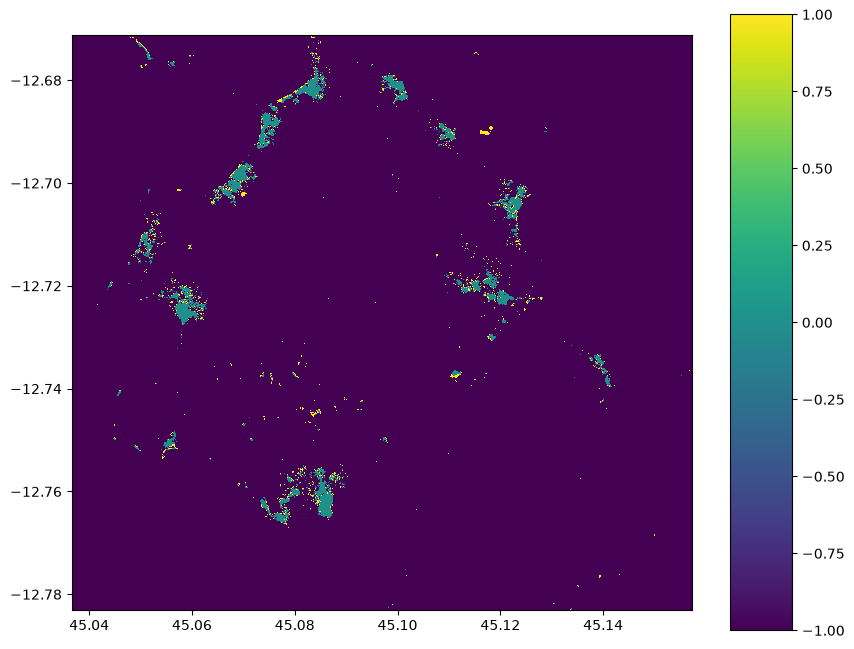

In [108]:
re.open("./images/eval.tif").visu("Classif_5_classes_classe4_EVO", colorbar=True, fig_size=(10, 10))

## <span style="color:red">Comparaison avec les variations d'indices spectraux</span>

# <span style="color:red">**Objectif 5 : Analyse environnementale à proximité des pièges à moustiques**</span>

## <span style="color:red">Caractérisation de l'occupation du sol autour des pièges</span>

## <span style="color:red">Quantification des variations d'occupation du sol autour des pièges entre 2019 et 2024</span>

## <span style="color:red">Les limites de l'interprétation écologique</span>

# <span style="color:red">**Objectif 6 : Risque et probabilité de présence (optionnel)**</span>